# TA-06 Pemodelan dan Simulasi: Dinamika Tangki Air dengan Lubang Bocor

Notebook ini berisi program yang sama dengan `main.py`, dipecah per langkah agar mudah dijelaskan.

**Model (ODE orde-1 nonlinier):** $A\,\dfrac{dh}{dt} = Q_{in}(t) - k\sqrt{h}$

| Kategori | Variabel |
|---|---|
| Input konstanta | $A$, $k$, $h_{max}$ |
| Input gangguan | tidak ada |
| Input sinyal kontrol | $Q_{in}(t)$ (step, impuls, ramp, sinusoida) |
| Output state / controlled variable | $h(t)$ |

DOF = 1 persamaan − 1 variabel tak diketahui = 0.

**Steady state:** $h_{ss} = (Q_{in}/k)^2$. **Metode numerik:** Euler, $h_{i+1} = h_i + \dfrac{dh}{dt}\,\Delta t$.

## 1. Parameter sistem

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

A = 0.20               # Luas penampang tangki (m^2)
Q_in_awal = 0.00015    # Debit masuk awal / basis (m^3/s)
Q_in_baru = 0.00020    # Debit masuk setelah step (m^3/s)
k = 0.0003             # Konstanta aliran keluar (m^2.5/s)
h0 = 0.05              # Tinggi awal air (m)
h_max = 0.60           # Tinggi maksimum tangki (m)

dt = 1                 # Langkah waktu (s)
t_step = 3600          # Waktu sinyal kontrol mulai diberikan (s)
t_end = 7200           # Total waktu simulasi (s)

# Parameter sinyal kontrol tambahan
Q_impuls = 0.00080     # Amplitudo impuls (m^3/s)
lebar_impuls = 60      # Lebar impuls (s)
durasi_ramp = 1800     # Lama ramp sampai mencapai Q_in_baru (s)
amp_sinus = 0.00005    # Amplitudo sinus (m^3/s)
periode_sinus = 1800   # Periode sinus (s)

os.makedirs("hasil_simulasi", exist_ok=True)

## 2. Sinyal kontrol $Q_{in}(t)$, simulasi Euler, dan fungsi plot

In [2]:
def sinyal_qin(t, mode):
    """Sinyal kontrol Q_in(t) untuk tiap jenis input."""
    if mode == "steady":
        return Q_in_awal
    if t < t_step:
        return Q_in_awal
    s = t - t_step                      # waktu sejak sinyal diberikan
    if mode == "step":
        return Q_in_baru
    if mode == "impulse":
        return Q_impuls if s < lebar_impuls else Q_in_awal
    if mode == "ramp":
        naik = (Q_in_baru - Q_in_awal) * min(s / durasi_ramp, 1.0)
        return Q_in_awal + naik
    if mode == "sinus":
        return Q_in_awal + amp_sinus * np.sin(2 * np.pi * s / periode_sinus)
    raise ValueError("Mode simulasi tidak dikenal")


def simulasi_tangki(mode):
    waktu = np.arange(0, t_end + dt, dt)
    tinggi = np.zeros(len(waktu))
    q_masuk = np.zeros(len(waktu))
    q_keluar = np.zeros(len(waktu))

    tinggi[0] = h0
    q_masuk[0] = sinyal_qin(waktu[0], mode)
    q_keluar[0] = k * np.sqrt(h0)

    for i in range(1, len(waktu)):
        qin = sinyal_qin(waktu[i - 1], mode)
        qout = k * np.sqrt(max(tinggi[i - 1], 0))
        dhdt = (qin - qout) / A
        tinggi[i] = max(0.0, tinggi[i - 1] + dhdt * dt)   # Euler + cegah h negatif

        q_masuk[i] = sinyal_qin(waktu[i], mode)
        q_keluar[i] = k * np.sqrt(tinggi[i])

    return waktu, tinggi, A * tinggi, q_masuk, q_keluar


def plot_respons(mode, judul, nama_file, garis_ss_baru=False):
    t, h, v, qin, qout = simulasi_tangki(mode)
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)

    ax1.plot(t / 60, h, color="blue", linewidth=2, label="Tinggi air h(t)")
    ax1.axhline(h_ss_awal, color="orange", linestyle="--", label="Steady state awal")
    if garis_ss_baru:
        ax1.axhline(h_ss_baru, color="green", linestyle="--", label="Steady state baru")
    ax1.axvline(t_step / 60, color="red", linestyle=":", label="Sinyal mulai (menit ke-60)")
    ax1.axhline(h_max, color="gray", linestyle="-.", linewidth=1, label="Kapasitas tangki")
    ax1.set_ylabel("Ketinggian Cairan h(t) (m)")
    ax1.set_title(judul)
    ax1.grid(True)
    ax1.legend(loc="upper left", bbox_to_anchor=(0.01, 0.9), fontsize=8)

    ax2.plot(t / 60, qin * 1000, "r--", linewidth=2, label="Q_in(t) (sinyal kontrol)")
    ax2.plot(t / 60, qout * 1000, "g-", linewidth=2, label="Q_out(t)")
    ax2.set_xlabel("Waktu (menit)")
    ax2.set_ylabel("Debit (L/s)")
    ax2.grid(True)
    ax2.legend(loc="upper left", fontsize=8)

    plt.tight_layout()
    plt.savefig(f"hasil_simulasi/{nama_file}", dpi=300)
    plt.show()
    return t, h, v

## 3. Steady state teoritis dan konstanta waktu

In [3]:
h_ss_awal = (Q_in_awal / k) ** 2
h_ss_baru = (Q_in_baru / k) ** 2

# Konstanta waktu hasil linearisasi di sekitar steady state: tau = 2*A*sqrt(h_ss)/k
tau_awal = 2 * A * np.sqrt(h_ss_awal) / k
tau_baru = 2 * A * np.sqrt(h_ss_baru) / k

print("====================================")
print("HASIL PERHITUNGAN STEADY STATE")
print("====================================")
print(f"Steady state awal : {h_ss_awal:.6f} m")
print(f"Steady state baru : {h_ss_baru:.6f} m")
print(f"Kapasitas tangki  : {h_max:.2f} m")
print(f"Konstanta waktu   : {tau_awal:.1f} s (awal), {tau_baru:.1f} s (baru)")
if h_ss_baru > h_max:
    print("PERINGATAN: steady state baru melebihi kapasitas tangki (tangki meluap)!")
else:
    print("Tangki aman: steady state di bawah kapasitas maksimum.")

HASIL PERHITUNGAN STEADY STATE
Steady state awal : 0.250000 m
Steady state baru : 0.444444 m
Kapasitas tangki  : 0.60 m
Konstanta waktu   : 666.7 s (awal), 888.9 s (baru)
Tangki aman: steady state di bawah kapasitas maksimum.


## 4. Simulasi steady state

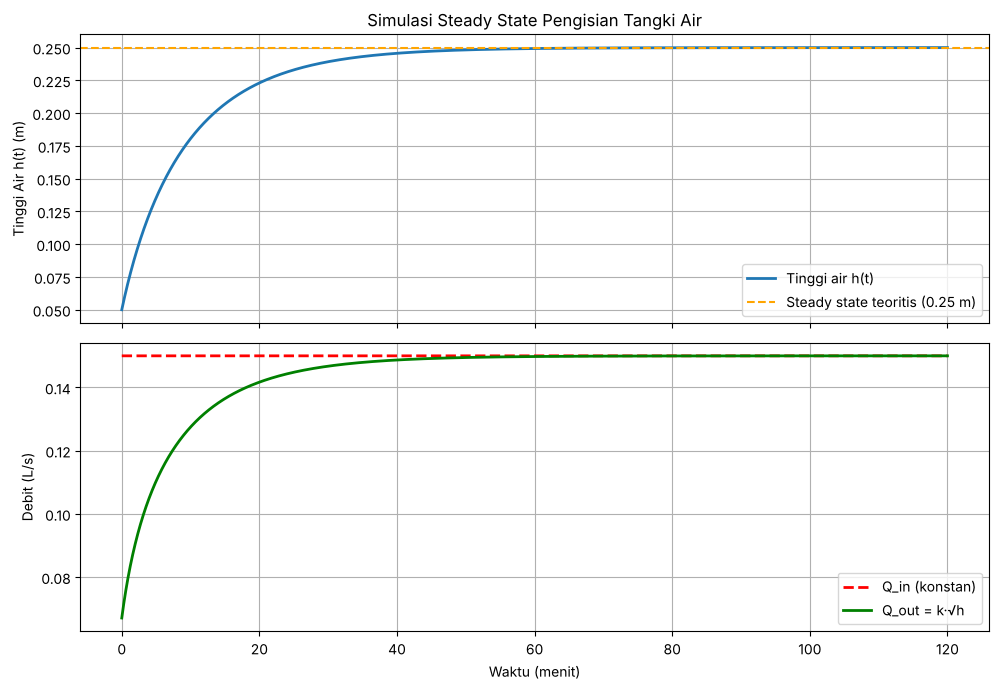

In [4]:
t1, h1, v1, qin1, qout1 = simulasi_tangki("steady")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax1.plot(t1 / 60, h1, linewidth=2, label="Tinggi air h(t)")
ax1.axhline(h_ss_awal, color="orange", linestyle="--",
            label=f"Steady state teoritis ({h_ss_awal:.2f} m)")
ax1.set_ylabel("Tinggi Air h(t) (m)")
ax1.set_title("Simulasi Steady State Pengisian Tangki Air")
ax1.grid(True)
ax1.legend()

ax2.plot(t1 / 60, qin1 * 1000, "r--", linewidth=2, label="Q_in (konstan)")
ax2.plot(t1 / 60, qout1 * 1000, "g-", linewidth=2, label="Q_out = k·√h")
ax2.set_xlabel("Waktu (menit)")
ax2.set_ylabel("Debit (L/s)")
ax2.grid(True)
ax2.legend()
plt.tight_layout()
plt.savefig("hasil_simulasi/grafik_steady_state.png", dpi=300)
plt.show()

## 5. Simulasi dengan sinyal kontrol: step, impuls, ramp, sinusoida

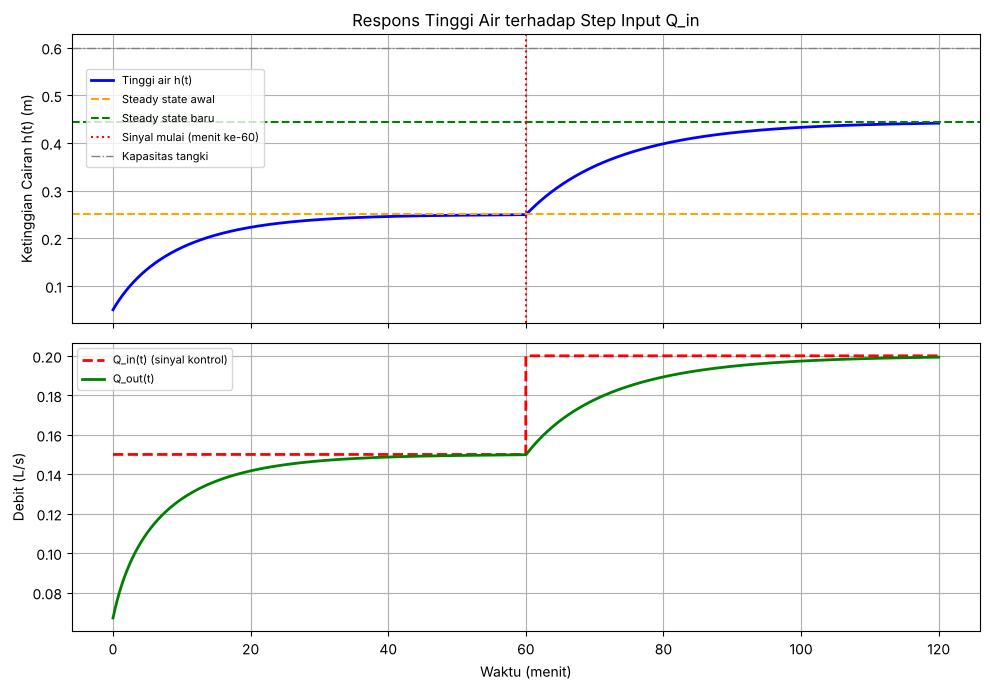

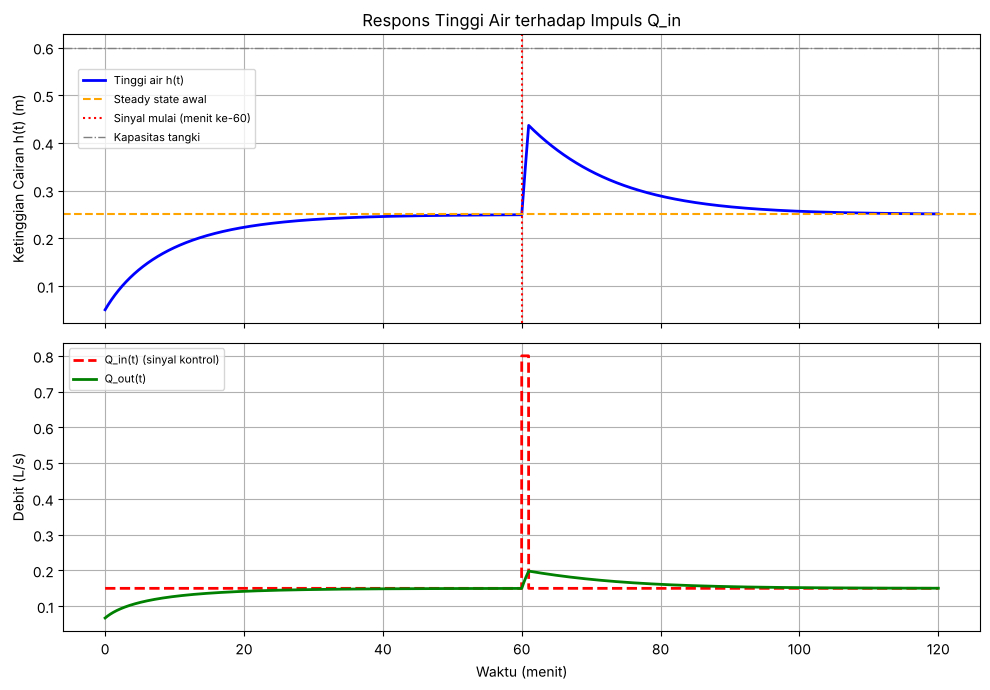

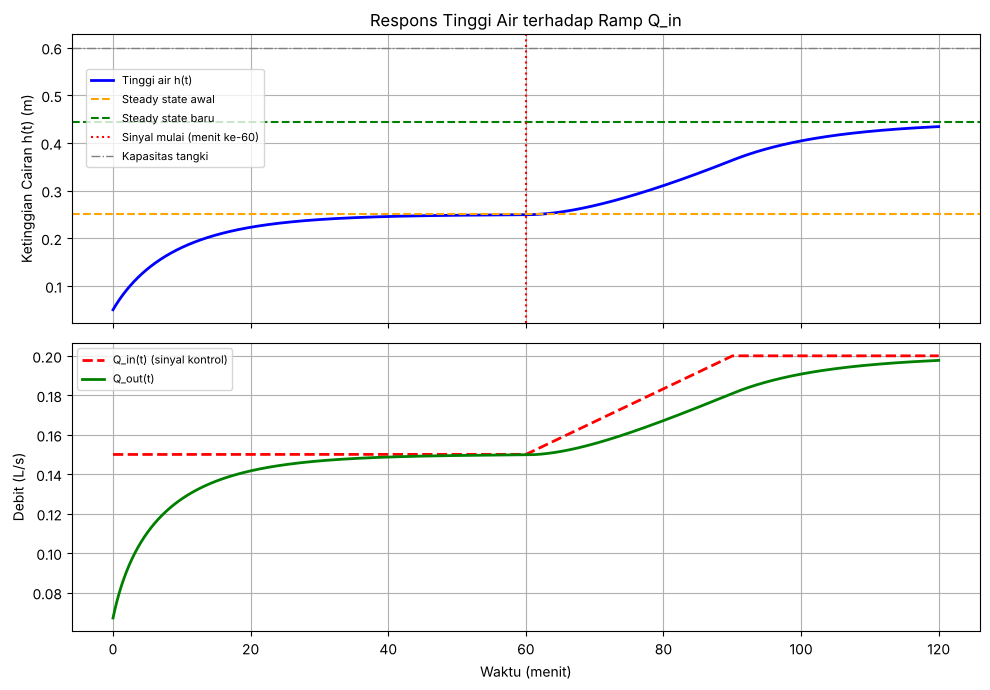

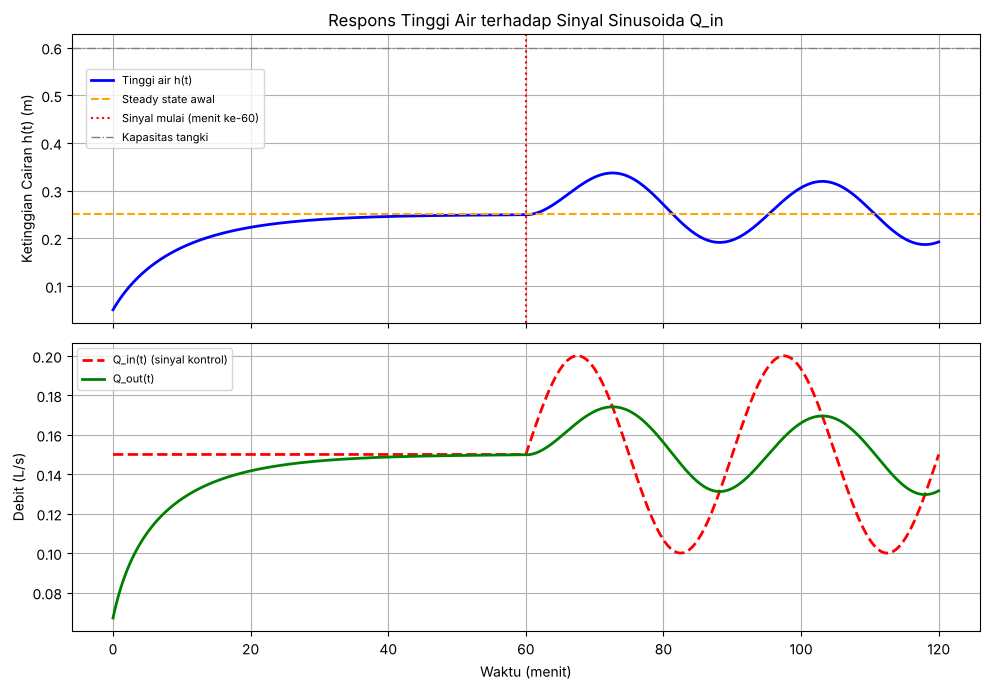

In [5]:
_, h_step, v_step = plot_respons(
    "step", "Respons Tinggi Air terhadap Step Input Q_in",
    "grafik_step_input.png", garis_ss_baru=True)

_, h_imp, _ = plot_respons(
    "impulse", "Respons Tinggi Air terhadap Impuls Q_in",
    "grafik_impulse_input.png")

_, h_ramp, _ = plot_respons(
    "ramp", "Respons Tinggi Air terhadap Ramp Q_in",
    "grafik_ramp_input.png", garis_ss_baru=True)

_, h_sin, _ = plot_respons(
    "sinus", "Respons Tinggi Air terhadap Sinyal Sinusoida Q_in",
    "grafik_sinus_input.png")

## 6. Ringkasan hasil

In [6]:
print("\n====================================")
print("HASIL SIMULASI")
print("====================================")
print(f"Tinggi akhir steady          : {h1[-1]:.6f} m")
print(f"Tinggi akhir step            : {h_step[-1]:.6f} m")
print(f"Tinggi puncak impuls         : {h_imp.max():.6f} m")
print(f"Tinggi akhir ramp            : {h_ramp[-1]:.6f} m")
print(f"Tinggi min/maks sinus (fase 2): {h_sin[t_step:].min():.4f} / {h_sin[t_step:].max():.4f} m")
for nama, h in [("step", h_step), ("impuls", h_imp), ("ramp", h_ramp), ("sinus", h_sin)]:
    if h.max() > h_max:
        print(f"PERINGATAN: tangki meluap pada simulasi {nama}!")
print("\nGrafik berhasil disimpan pada folder hasil_simulasi.")


HASIL SIMULASI
Tinggi akhir steady          : 0.249997 m
Tinggi akhir step            : 0.441422 m
Tinggi puncak impuls         : 0.436767 m
Tinggi akhir ramp            : 0.434219 m
Tinggi min/maks sinus (fase 2): 0.1868 / 0.3370 m

Grafik berhasil disimpan pada folder hasil_simulasi.


## 7. Interpretasi singkat
- **Steady state:** $h$ naik dari 0,05 m menuju 0,25 m, tempat $Q_{out}=Q_{in}$.
- **Step:** $h$ menuju steady state baru 0,4444 m, bertahap karena sifat akumulasi tangki.
- **Impuls:** $h$ melonjak lalu kembali ke 0,25 m (gangguan sesaat tidak mengubah steady state).
- **Ramp:** $h$ naik landai dan tertinggal dari $Q_{in}$.
- **Sinusoida:** $h$ berosilasi dengan amplitudo teredam dan fase tertinggal ± 5 menit.